# 🛰️ High-Resolution Satellite Oil Storage Tank Detection using YOLO11s (Small)

This notebook trains **YOLO11-Small (`yolo11s.pt`)** with boundary-preserving tiling, comprehensive evaluation graphs & error analysis, and full satellite scene sliced inference using **SAHI**.


In [53]:
!pip install ultralytics opencv-python sahi


In [54]:
import os
import cv2
import random
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

# Ensure full reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    print(f"CUDA Device: {torch.cuda.get_device_name(0)}")


CUDA Device: Tesla T4


In [55]:
# Support both Kaggle environment and local environment
kaggle_path = "/kaggle/input/datasets/organizations/airbusgeo/airbus-oil-storage-detection-dataset"
local_path = "./data"

if os.path.exists(kaggle_path):
    base_path = kaggle_path
elif os.path.exists(local_path):
    base_path = local_path
else:
    base_path = kaggle_path

print(f"Dataset path: {base_path}")
image_dir = os.path.join(base_path, "images")
csv_path = os.path.join(base_path, "annotations.csv")

df = pd.read_csv(csv_path)
print(f"Total annotations loaded: {len(df)}")
df.head()


Dataset path: /kaggle/input/datasets/organizations/airbusgeo/airbus-oil-storage-detection-dataset
Total annotations loaded: 13592


,image_id,class,bounds
0,0918a15c-8cfb-4da7-92cf-1f5098a76760,oil-storage-tank,"(1205, 1493, 1231, 1516)"
1,0918a15c-8cfb-4da7-92cf-1f5098a76760,oil-storage-tank,"(1479, 1756, 1507, 1776)"
2,0918a15c-8cfb-4da7-92cf-1f5098a76760,oil-storage-tank,"(1478, 1786, 1518, 1815)"
3,0918a15c-8cfb-4da7-92cf-1f5098a76760,oil-storage-tank,"(2132, 2163, 2148, 2178)"
4,0918a15c-8cfb-4da7-92cf-1f5098a76760,oil-storage-tank,"(2010, 2127, 2024, 2141)"


In [56]:
def parse_bounds(bounds_str):
    bounds_str = bounds_str.strip("()")
    x_min, y_min, x_max, y_max = map(int, bounds_str.split(","))
    return [x_min, y_min, x_max, y_max]


In [57]:
def convert_to_yolo(size, bbox):
    w_img, h_img = size
    x_center = (bbox[0] + bbox[2]) / 2.0 / w_img
    y_center = (bbox[1] + bbox[3]) / 2.0 / h_img
    w = (bbox[2] - bbox[0]) / float(w_img)
    h = (bbox[3] - bbox[1]) / float(h_img)
    return [x_center, y_center, w, h]


In [58]:
# Deterministic Train / Validation Split (80/20)
random.seed(SEED)
image_ids = sorted(df['image_id'].unique().tolist())
random.shuffle(image_ids)

split = int(0.8 * len(image_ids))
train_ids = set(image_ids[:split])
val_ids = set(image_ids[split:])

print(f"Total unique images: {len(image_ids)}")
print(f"Train images: {len(train_ids)} | Validation images: {len(val_ids)}")


Total unique images: 98
Train images: 78 | Validation images: 20


In [59]:
os.makedirs("tiled/images/train", exist_ok=True)
os.makedirs("tiled/images/val", exist_ok=True)
os.makedirs("tiled/labels/train", exist_ok=True)
os.makedirs("tiled/labels/val", exist_ok=True)


In [60]:
# Tiling parameters with boundary preservation & background sampling
TILE_SIZE = 640
STRIDE = 512
MIN_BOX_SIZE = 10
BG_TILE_RATIO = 0.10  # 10% negative background tiles to suppress false positives


In [61]:
def get_steps(dimension, tile_size, stride):
    """Guarantees that boundary edge pixels are never dropped."""
    if dimension <= tile_size:
        return [0]
    steps = list(range(0, dimension - tile_size + 1, stride))
    if steps[-1] != dimension - tile_size:
        steps.append(dimension - tile_size)
    return steps

def tile_image_and_boxes_clean(img, boxes, bg_ratio=0.10):
    h, w, _ = img.shape
    tiles = []
    x_steps = get_steps(w, TILE_SIZE, STRIDE)
    y_steps = get_steps(h, TILE_SIZE, STRIDE)

    for y in y_steps:
        for x in x_steps:
            tile = img[y:y+TILE_SIZE, x:x+TILE_SIZE]
            tile_boxes = []

            for box in boxes:
                x_min, y_min, x_max, y_max = box
                if x_max <= x or x_min >= x + TILE_SIZE:
                    continue
                if y_max <= y or y_min >= y + TILE_SIZE:
                    continue

                new_xmin = max(x_min - x, 0)
                new_ymin = max(y_min - y, 0)
                new_xmax = min(x_max - x, TILE_SIZE)
                new_ymax = min(y_max - y, TILE_SIZE)

                box_w = new_xmax - new_xmin
                box_h = new_ymax - new_ymin
                if box_w < MIN_BOX_SIZE or box_h < MIN_BOX_SIZE:
                    continue

                tile_boxes.append([new_xmin, new_ymin, new_xmax, new_ymax])

            if len(tile_boxes) > 0:
                tiles.append((tile, tile_boxes))
            elif bg_ratio > 0 and random.random() < bg_ratio:
                tiles.append((tile, []))

    return tiles


In [62]:
tile_count = 0
tank_tile_count = 0
bg_tile_count = 0

for img_id in tqdm(image_ids):
    img_path = os.path.join(image_dir, f"{img_id}.jpg")
    if not os.path.exists(img_path):
        continue

    img = cv2.imread(img_path)
    if img is None:
        continue

    rows = df[df['image_id'] == img_id]
    boxes = [parse_bounds(r['bounds']) for _, r in rows.iterrows()]

    subset = "train" if img_id in train_ids else "val"
    ratio = BG_TILE_RATIO if subset == "train" else 0.05
    tiles = tile_image_and_boxes_clean(img, boxes, bg_ratio=ratio)

    for i, (tile, tile_boxes) in enumerate(tiles):
        h, w, _ = tile.shape
        img_name = f"{img_id}_{i}.jpg"
        label_name = f"{img_id}_{i}.txt"

        img_out = f"tiled/images/{subset}/{img_name}"
        label_out = f"tiled/labels/{subset}/{label_name}"

        cv2.imwrite(img_out, tile)
        with open(label_out, "w") as f:
            for box in tile_boxes:
                yolo_box = convert_to_yolo((w, h), box)
                f.write(f"0 {' '.join(map(str, yolo_box))}\n")

        tile_count += 1
        if len(tile_boxes) > 0:
            tank_tile_count += 1
        else:
            bg_tile_count += 1

print(f"Total tiles created: {tile_count}")
print(f"Tiles with tanks: {tank_tile_count}")
print(f"Background (empty) tiles: {bg_tile_count} ({bg_tile_count / max(1, tile_count):.1%})")


100%|██████████| 98/98 [00:07<00:00, 12.50it/s]

Total tiles created: 1185
Tiles with tanks: 1067
Background (empty) tiles: 118 (10.0%)


In [63]:
train_labels = glob.glob("tiled/labels/train/*.txt")
val_labels = glob.glob("tiled/labels/val/*.txt")

train_non_empty = sum(1 for f in train_labels if open(f).read().strip())
train_empty = len(train_labels) - train_non_empty

val_non_empty = sum(1 for f in val_labels if open(f).read().strip())
val_empty = len(val_labels) - val_non_empty

print(f"Train Tiles: {len(train_labels)} total | {train_non_empty} tanks | {train_empty} background ({train_empty / max(1, len(train_labels)):.1%})")
print(f"Val Tiles:   {len(val_labels)} total | {val_non_empty} tanks | {val_empty} background")


Train Tiles: 958 total | 856 tanks | 102 background (10.6%)
Val Tiles:   227 total | 211 tanks | 16 background


In [64]:
yaml_content = """
path: tiled
train: images/train
val: images/val

names:
  0: oil_tank
"""

with open("tiled_dataset.yaml", "w") as f:
    f.write(yaml_content)


## 🚀 Train YOLO11-Small (`yolo11s.pt`)

YOLO11s (9.4M parameters) offers the ideal balance for ~1,000 satellite tiles—delivering high mAP without the overfitting observed on larger Medium models.


In [65]:
from ultralytics import YOLO

# Load pretrained YOLO11-Small
model = YOLO("yolo11s.pt")

train_results = model.train(
    data="tiled_dataset.yaml",
    epochs=100,
    imgsz=640,
    batch=16,            # Optimized for Tesla T4 (16GB VRAM)
    patience=35,         # Ample patience to pass the mid-training plateau
    cos_lr=True,         # Cosine learning rate scheduler
    degrees=90,          # Nadir satellite rotational invariance
    flipud=0.5,
    fliplr=0.5,
    mosaic=1.0,
    close_mosaic=10,     # Turn off mosaic last 10 epochs for sharp boundaries
    plots=True,          # Ensure plots are tracked
    name="yolo11s_oil_tank"
)

# Grab the exact directory where Ultralytics saved everything
if hasattr(model, 'trainer') and model.trainer is not None:
    run_dir = str(model.trainer.save_dir)
else:
    all_runs = sorted(glob.glob("runs/detect/yolo11s_oil_tank*"))
    run_dir = all_runs[-1] if all_runs else "runs/detect/train"

print(f"\nTraining complete! Results saved in: {run_dir}")

# Force generation of PR curve, F1 curve, and Confusion Matrix on best checkpoint
print("\n--- Running Validation on best.pt with plots=True ---")
best_model_path = os.path.join(run_dir, "weights/best.pt")
best_model = YOLO(best_model_path)
best_val_metrics = best_model.val(data="tiled_dataset.yaml", plots=True)


Ultralytics 8.4.197 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=tiled_dataset.yaml, degrees=90, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_oil_tank, nbs=64, nms=None, opset=None, optimize=False, optimize

## 📊 Model Performance, Training Results & Error Analysis

This section extracts and visualizes the model performance metrics, learning curves, Precision-Recall trade-offs, and normalized confusion matrix in numbers and graphs.


In [66]:
# 1. Model Performance Summary in Numbers & Structured Table
if 'run_dir' not in locals():
    all_runs = sorted(glob.glob("runs/detect/yolo11s_oil_tank*"))
    run_dir = all_runs[-1] if all_runs else "runs/detect/train"

csv_file = os.path.join(run_dir, "results.csv")

if os.path.exists(csv_file):
    res_df = pd.read_csv(csv_file)
    res_df.columns = [c.strip() for c in res_df.columns]

    # Find the epoch with best mAP@50-95
    best_row_idx = res_df['metrics/mAP50-95(B)'].idxmax()
    best_row = res_df.loc[best_row_idx]
    
    p = best_row['metrics/precision(B)']
    r = best_row['metrics/recall(B)']
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0

    perf_summary = {
        "Metric": [
            "Best Epoch",
            "Precision (P)",
            "Recall (R)",
            "F1-Score",
            "mAP @ 0.50 (IoU=0.50)",
            "mAP @ 0.50:0.95 (Primary Benchmark)",
            "Final Train Box Loss",
            "Final Val Box Loss",
            "Final Train Cls Loss",
            "Final Val Cls Loss"
        ],
        "Value": [
            f"{int(best_row['epoch'])} / {len(res_df)}",
            f"{p:.4f} ({p*100:.2f}%)",
            f"{r:.4f} ({r*100:.2f}%)",
            f"{f1:.4f} ({f1*100:.2f}%)",
            f"{best_row['metrics/mAP50(B)']:.4f} ({best_row['metrics/mAP50(B)']*100:.2f}%)",
            f"{best_row['metrics/mAP50-95(B)']:.4f} ({best_row['metrics/mAP50-95(B)']*100:.2f}%)",
            f"{best_row['train/box_loss']:.4f}",
            f"{best_row['val/box_loss']:.4f}",
            f"{best_row['train/cls_loss']:.4f}",
            f"{best_row['val/cls_loss']:.4f}"
        ]
    }
    
    summary_df = pd.DataFrame(perf_summary)
    print("=" * 65)
    print("🎯 YOLO11s MODEL PERFORMANCE SUMMARY (BEST EPOCH)")
    print("=" * 65)
    display(summary_df)
else:
    print(f"results.csv not found at {csv_file}. Please complete training first.")


🎯 YOLO11s MODEL PERFORMANCE SUMMARY (BEST EPOCH)


,Metric,Value
0,Best Epoch,78 / 100
1,Precision (P),0.9183 (91.83%)
2,Recall (R),0.8995 (89.95%)
3,F1-Score,0.9088 (90.88%)
4,mAP @ 0.50 (IoU=0.50),0.9497 (94.97%)
5,mAP @ 0.50:0.95 (Primary Benchmark),0.6454 (64.54%)
6,Final Train Box Loss,0.9572
7,Final Val Box Loss,1.0151
8,Final Train Cls Loss,0.4797
9,Final Val Cls Loss,0.5146


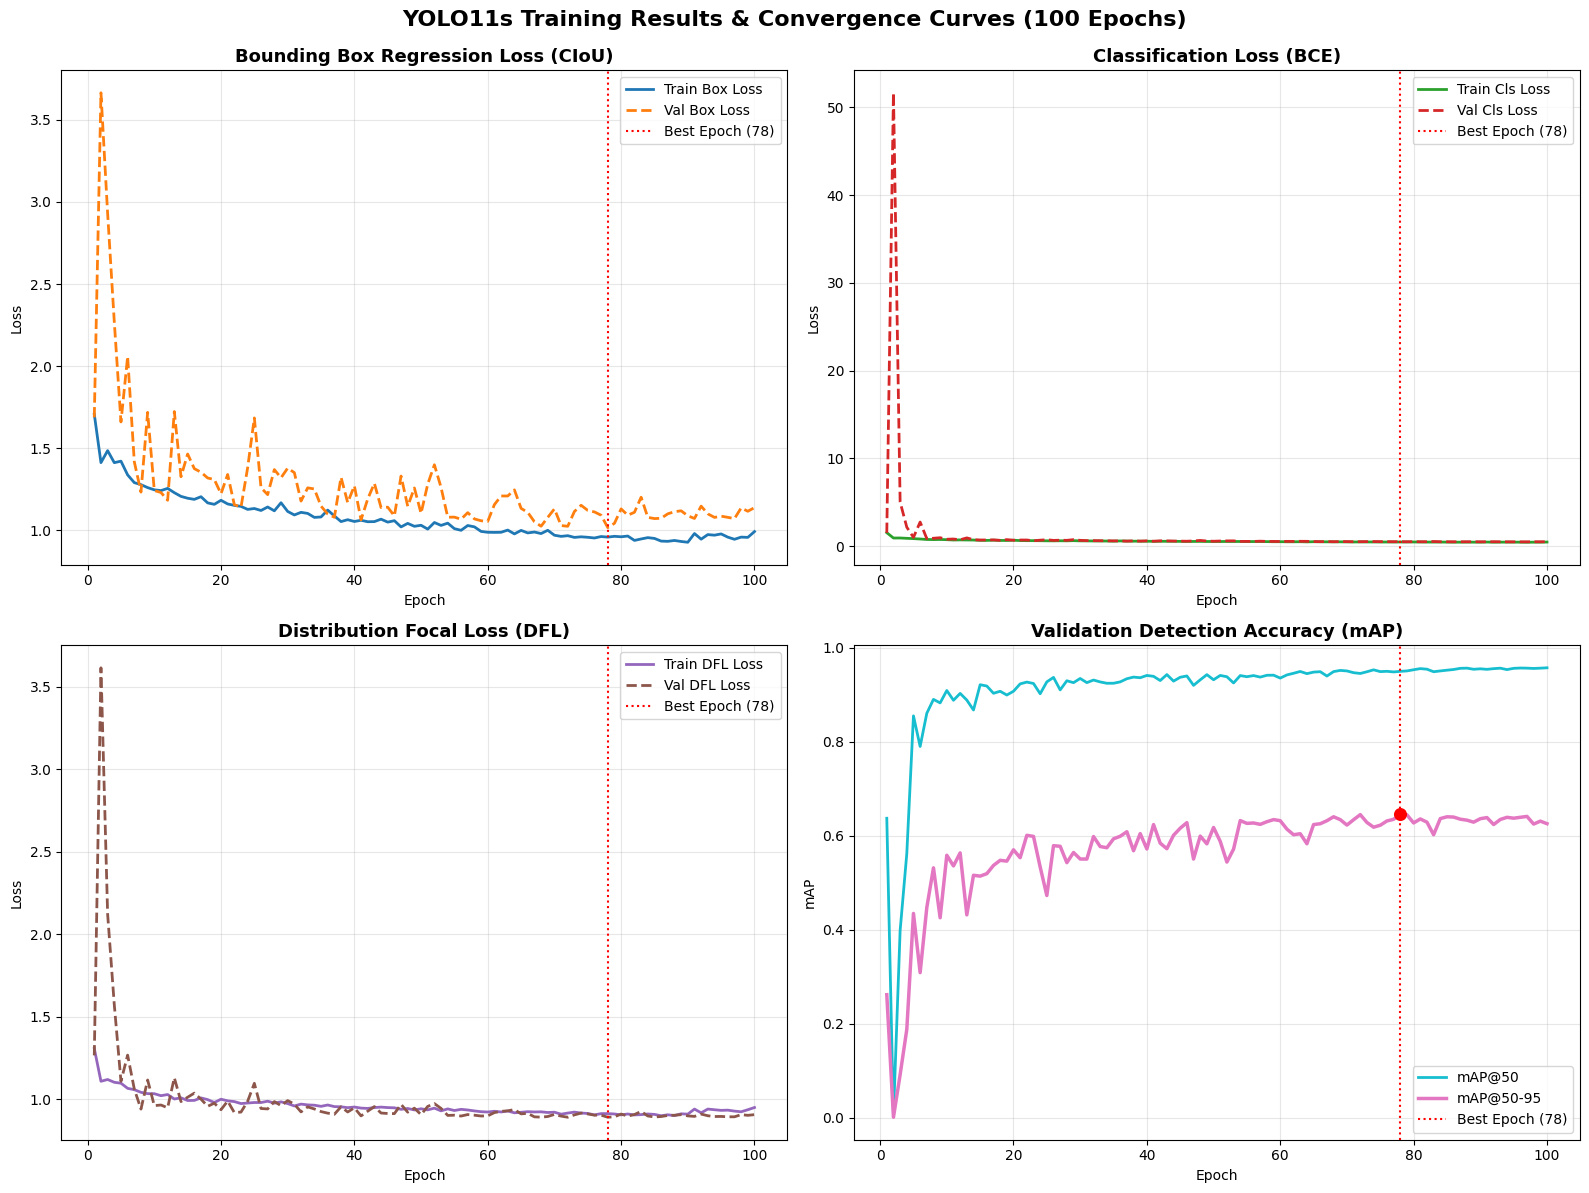

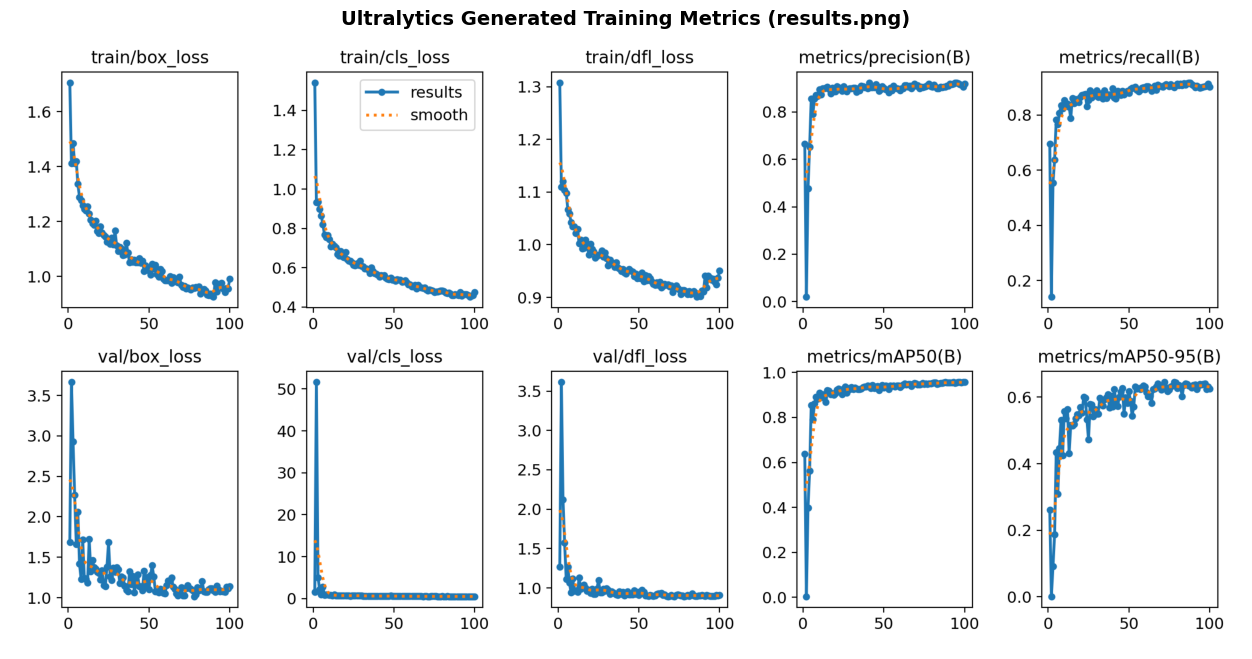

In [67]:
# 2. Training Results & Learning Curves (Losses & Accuracy across Epochs)
if os.path.exists(csv_file):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    epochs = res_df['epoch']
    best_ep = int(best_row['epoch'])

    # Subplot 1: Bounding Box Loss
    axes[0, 0].plot(epochs, res_df['train/box_loss'], label='Train Box Loss', color='#1f77b4', lw=2)
    axes[0, 0].plot(epochs, res_df['val/box_loss'], label='Val Box Loss', color='#ff7f0e', lw=2, linestyle='--')
    axes[0, 0].axvline(best_ep, color='red', linestyle=':', label=f'Best Epoch ({best_ep})')
    axes[0, 0].set_title('Bounding Box Regression Loss (CIoU)', fontsize=13, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()

    # Subplot 2: Classification Loss
    axes[0, 1].plot(epochs, res_df['train/cls_loss'], label='Train Cls Loss', color='#2ca02c', lw=2)
    axes[0, 1].plot(epochs, res_df['val/cls_loss'], label='Val Cls Loss', color='#d62728', lw=2, linestyle='--')
    axes[0, 1].axvline(best_ep, color='red', linestyle=':', label=f'Best Epoch ({best_ep})')
    axes[0, 1].set_title('Classification Loss (BCE)', fontsize=13, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()

    # Subplot 3: Distribution Focal Loss (DFL)
    axes[1, 0].plot(epochs, res_df['train/dfl_loss'], label='Train DFL Loss', color='#9467bd', lw=2)
    axes[1, 0].plot(epochs, res_df['val/dfl_loss'], label='Val DFL Loss', color='#8c564b', lw=2, linestyle='--')
    axes[1, 0].axvline(best_ep, color='red', linestyle=':', label=f'Best Epoch ({best_ep})')
    axes[1, 0].set_title('Distribution Focal Loss (DFL)', fontsize=13, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()

    # Subplot 4: Detection Accuracy (mAP@50 and mAP@50-95)
    axes[1, 1].plot(epochs, res_df['metrics/mAP50(B)'], label='mAP@50', color='#17becf', lw=2)
    axes[1, 1].plot(epochs, res_df['metrics/mAP50-95(B)'], label='mAP@50-95', color='#e377c2', lw=2.5)
    axes[1, 1].axvline(best_ep, color='red', linestyle=':', label=f'Best Epoch ({best_ep})')
    axes[1, 1].scatter([best_ep], [best_row['metrics/mAP50-95(B)']], color='red', s=70, zorder=5)
    axes[1, 1].set_title('Validation Detection Accuracy (mAP)', fontsize=13, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('mAP')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()

    plt.suptitle(f'YOLO11s Training Results & Convergence Curves ({len(res_df)} Epochs)', fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

# Display Ultralytics combined results.png
ultralytics_results_img = os.path.join(run_dir, "results.png")
if os.path.exists(ultralytics_results_img):
    plt.figure(figsize=(16, 8))
    plt.imshow(Image.open(ultralytics_results_img))
    plt.title("Ultralytics Generated Training Metrics (results.png)", fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()


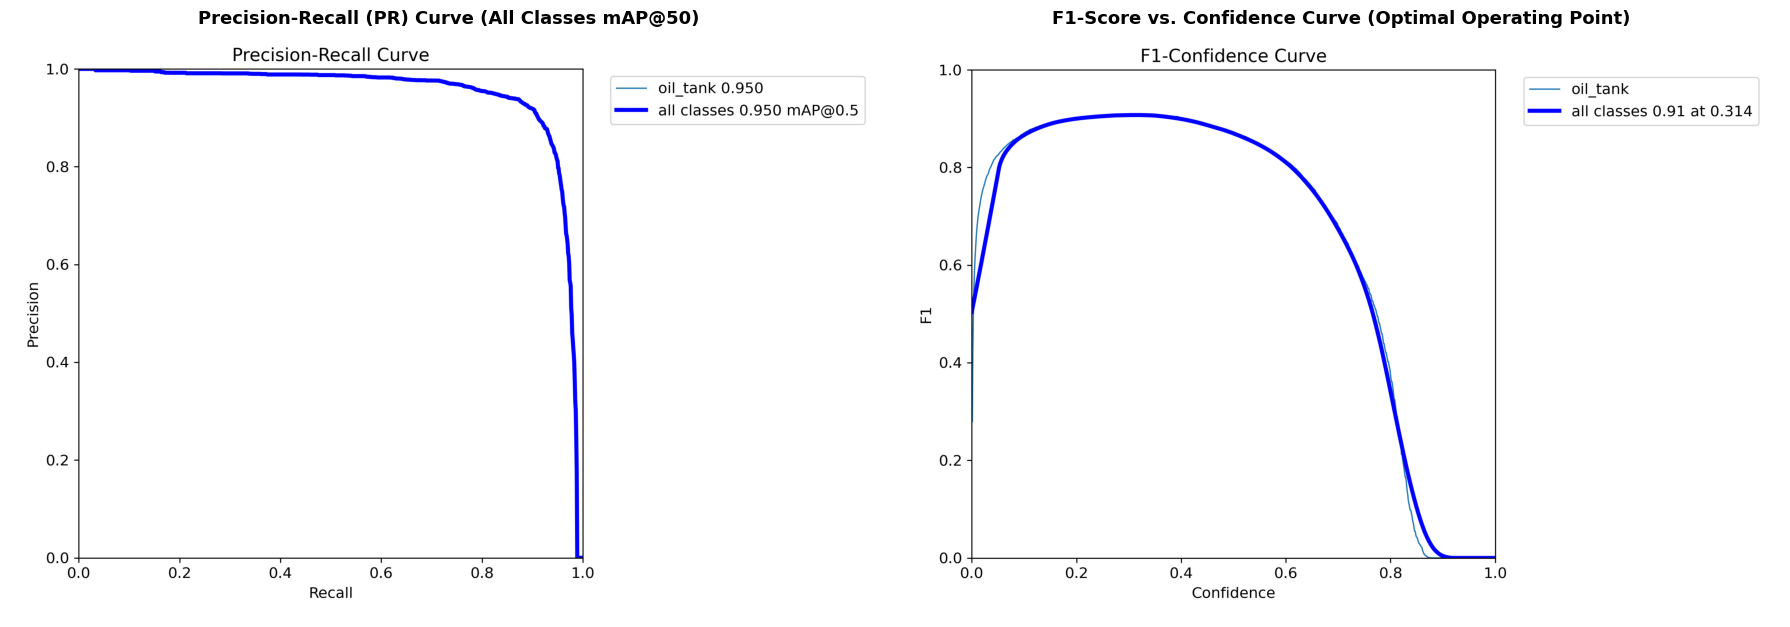

In [68]:
# 3. Precision-Recall Curve & F1-Confidence Curve
pr_curve_path = os.path.join(run_dir, "BoxPR_curve.png")
f1_curve_path = os.path.join(run_dir, "BoxF1_curve.png")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

if os.path.exists(pr_curve_path):
    axes[0].imshow(Image.open(pr_curve_path))
    axes[0].set_title("Precision-Recall (PR) Curve (All Classes mAP@50)", fontsize=13, fontweight='bold')
    axes[0].axis('off')
else:
    axes[0].text(0.5, 0.5, "BoxPR_curve.png not found. Run model.val(plots=True) to generate.", ha='center')

if os.path.exists(f1_curve_path):
    axes[1].imshow(Image.open(f1_curve_path))
    axes[1].set_title("F1-Score vs. Confidence Curve (Optimal Operating Point)", fontsize=13, fontweight='bold')
    axes[1].axis('off')
else:
    axes[1].text(0.5, 0.5, "BoxF1_curve.png not found. Run model.val(plots=True) to generate.", ha='center')

plt.tight_layout()
plt.show()


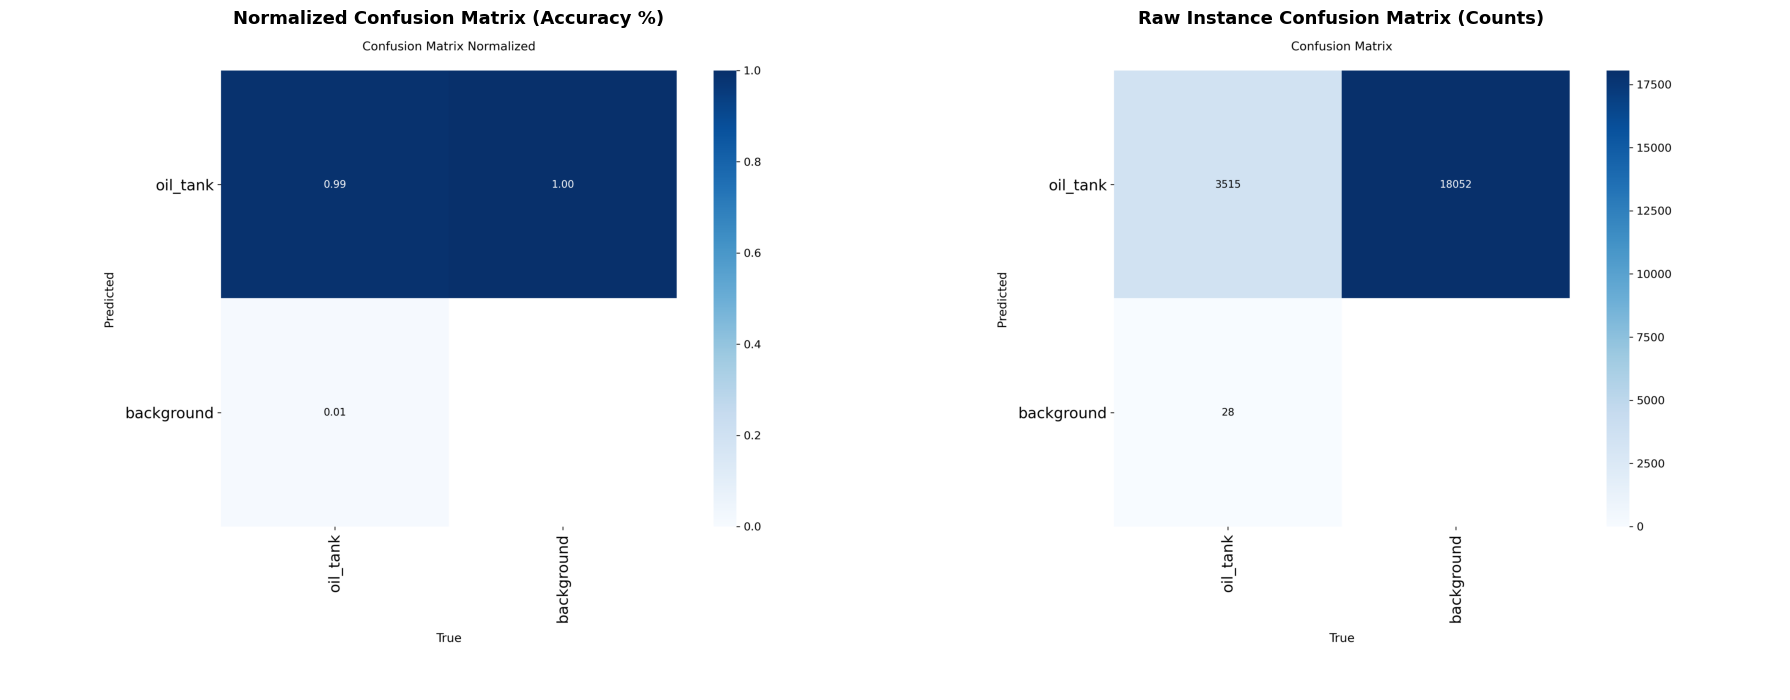

In [69]:
# 4. Error Analysis & Normalized Confusion Matrix
conf_norm_path = os.path.join(run_dir, "confusion_matrix_normalized.png")
conf_path = os.path.join(run_dir, "confusion_matrix.png")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

if os.path.exists(conf_norm_path):
    axes[0].imshow(Image.open(conf_norm_path))
    axes[0].set_title("Normalized Confusion Matrix (Accuracy %)", fontsize=13, fontweight='bold')
    axes[0].axis('off')
else:
    axes[0].text(0.5, 0.5, "confusion_matrix_normalized.png not found", ha='center')

if os.path.exists(conf_path):
    axes[1].imshow(Image.open(conf_path))
    axes[1].set_title("Raw Instance Confusion Matrix (Counts)", fontsize=13, fontweight='bold')
    axes[1].axis('off')
else:
    axes[1].text(0.5, 0.5, "confusion_matrix.png not found", ha='center')

plt.tight_layout()
plt.show()


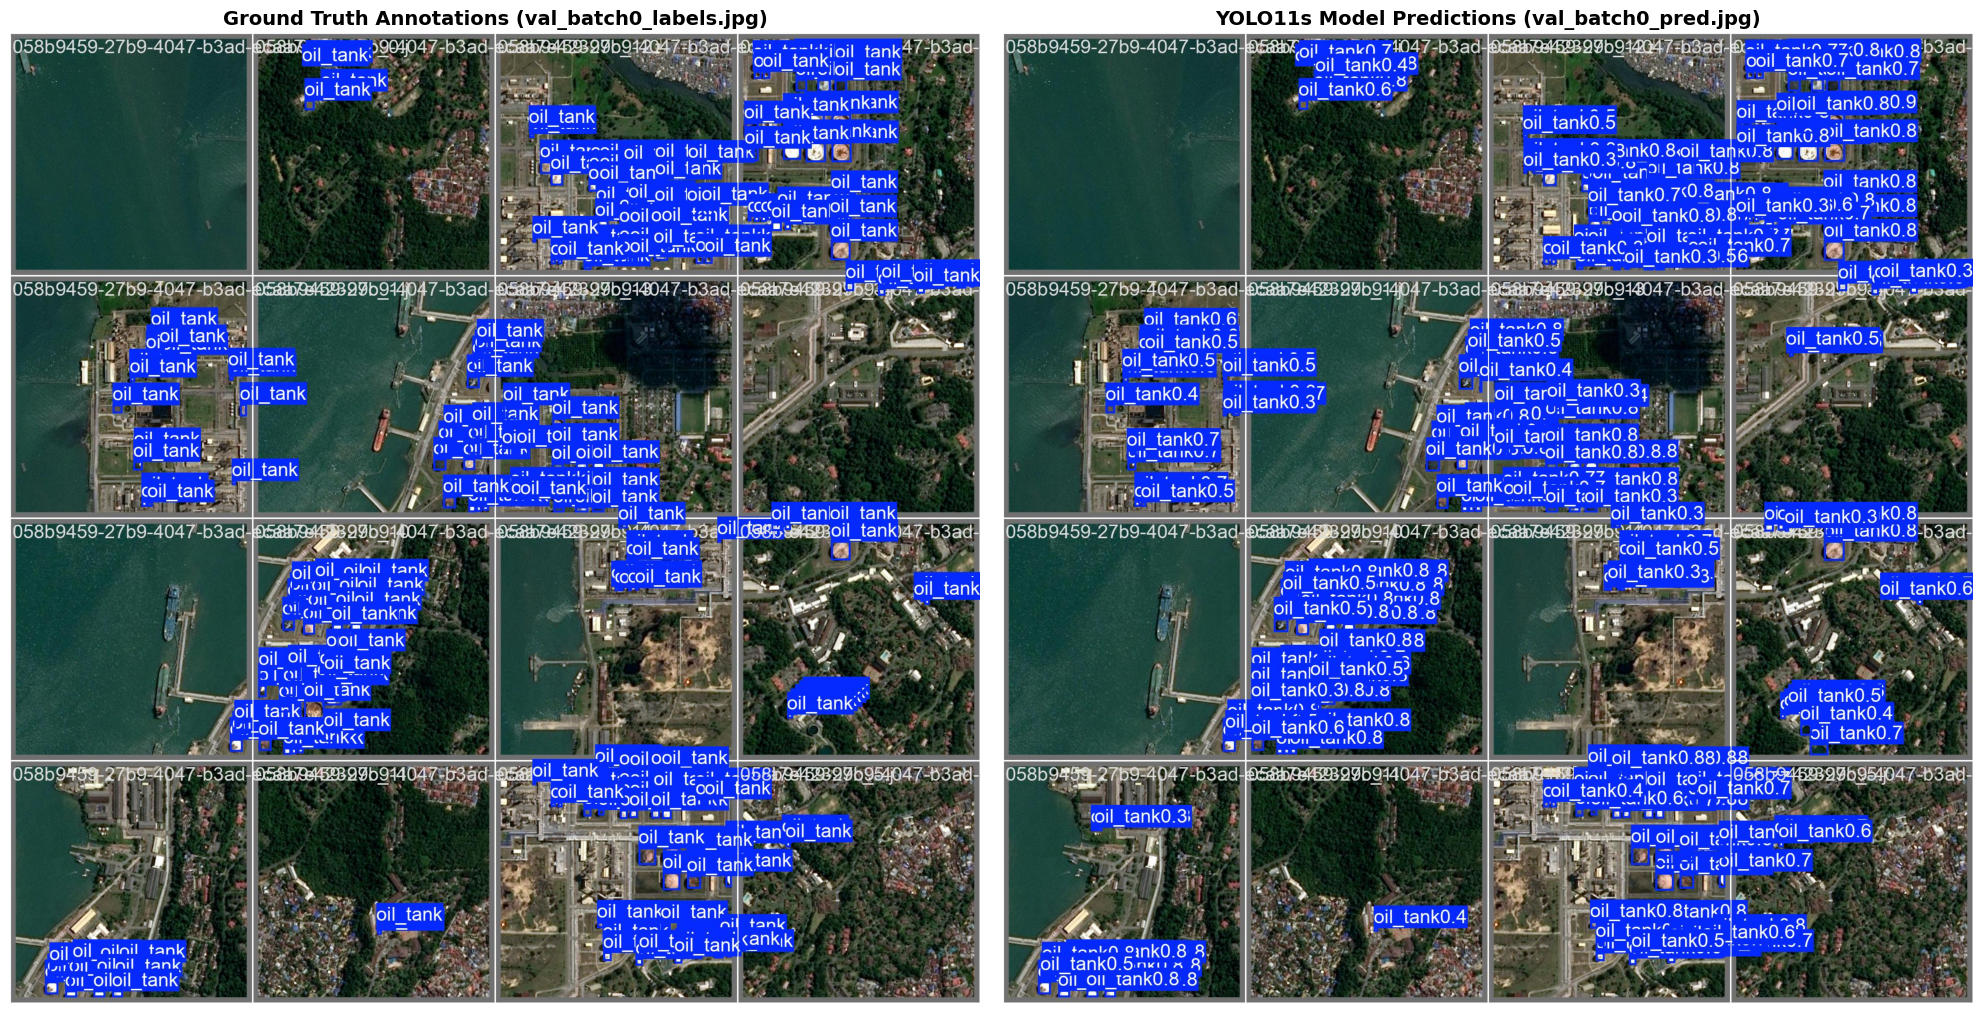

In [70]:
# 5. Visual Inspection: Ground Truth Labels vs. Model Predictions (Validation Batch)
val_batch_labels = os.path.join(run_dir, "val_batch0_labels.jpg")
val_batch_pred = os.path.join(run_dir, "val_batch0_pred.jpg")

if os.path.exists(val_batch_labels) and os.path.exists(val_batch_pred):
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))
    
    axes[0].imshow(Image.open(val_batch_labels))
    axes[0].set_title("Ground Truth Annotations (val_batch0_labels.jpg)", fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(Image.open(val_batch_pred))
    axes[1].set_title("YOLO11s Model Predictions (val_batch0_pred.jpg)", fontsize=14, fontweight='bold')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("Validation batch comparison images not found.")


In [71]:
# Tile-level predictions on the validation set
results = best_model.predict(
    source="tiled/images/val",
    conf=0.55,
    iou=0.3,
    max_det=300,
    save=True,
    save_txt=True
)



image 1/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_0.jpg: 640x640 (no detections), 15.4ms
image 2/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_1.jpg: 640x640 13 oil_tanks, 15.5ms
image 3/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_10.jpg: 640x640 3 oil_tanks, 15.5ms
image 4/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_11.jpg: 640x640 12 oil_tanks, 15.4ms
image 5/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_12.jpg: 640x640 5 oil_tanks, 15.5ms
image 6/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_13.jpg: 640x640 14 oil_tanks, 15.4ms
image 7/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_14.jpg: 640x640 32 oil_tanks, 15.5ms
image 8/227 /kaggle/working/tiled/images/val/058b9459-27b9-4047-b3ad-ecaa7e42399c_15.jpg: 640x640 (no detections), 15.4ms
image 9/227 /kaggle/working/tiled/images/val/

## 🛰️ Full-Image Sliced Inference (SAHI) with YOLO11s

Runs dynamic sliced prediction on high-resolution satellite scenes with Global NMS merging duplicate detections across slice boundaries.


In [72]:
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from sahi.utils.cv import read_image
from PIL import Image

# Initialize SAHI with trained YOLO11s best weights
detection_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8',  # SAHI ultralytics backend seamlessly handles yolo11 weights
    model_path=best_model_path,
    confidence_threshold=0.5,
    device='cuda:0' if torch.cuda.is_available() else 'cpu'
)

print(f"SAHI Detection Model ready with weights: {best_model_path}")


SAHI Detection Model ready with weights: /kaggle/working/runs/detect/yolo11s_oil_tank/weights/best.pt


In [ ]:
def run_sahi_inference(image_path, model, slice_size=640, overlap_ratio=0.25, output_dir="runs/detect/sahi_output"):
    os.makedirs(output_dir, exist_ok=True)
    filename = os.path.basename(image_path)
    
    print(f"Running SAHI sliced inference on: {filename}")
    result = get_sliced_prediction(
        image_path,
        model,
        slice_height=slice_size,
        slice_width=slice_size,
        overlap_height_ratio=overlap_ratio,
        overlap_width_ratio=overlap_ratio,
        perform_standard_pred=False,
        postprocess_type="NMS",
        postprocess_match_metric="IOU",
        postprocess_match_threshold=0.3
    )
    
    num_tanks = len(result.object_prediction_list)
    print(f"-> Detected {num_tanks} oil storage tanks.")
    result.export_visuals(export_dir=output_dir, text_size=None)
    return result

sample_val_id = next(iter(val_ids))
sample_image_path = os.path.join(image_dir, f"{sample_val_id}.jpg")

if os.path.exists(sample_image_path):
    sahi_result = run_sahi_inference(
        image_path=sample_image_path,
        model=detection_model,
        slice_size=640,
        overlap_ratio=0.25
    )
    
    plt.figure(figsize=(14, 14))
    pred_vis = os.path.join("runs/detect/sahi_output", "prediction_visual.png")
    if os.path.exists(pred_vis):
        vis_img = Image.open(pred_vis)
        plt.imshow(vis_img)
        plt.title(f"YOLO11s Full-Image SAHI Inference | Detected Tanks: {len(sahi_result.object_prediction_list)}", fontsize=14)
        plt.axis('off')
        plt.show()


Running SAHI sliced inference on: 52a4f0b4-bd4c-40cc-a54d-9528213b28be.jpg
Performing prediction on 25 slices.
-> Detected 44 oil storage tanks.


In [76]:
# Benchmark: Unsliced vs. Sliced (SAHI) with YOLO11s
if 'sample_image_path' in locals() and os.path.exists(sample_image_path):
    raw_results = best_model.predict(source=sample_image_path, conf=0.5, imgsz=640, verbose=False)
    raw_count = len(raw_results[0].boxes)
    sahi_count = len(sahi_result.object_prediction_list)

    print("="*55)
    print("🛰️ BENCHMARK: Unsliced vs. Sliced Inference (YOLO11s)")
    print(f"Image: {os.path.basename(sample_image_path)}")
    print(f"Standard Unsliced YOLO11s (downscaled to 640x640): {raw_count} tanks")
    print(f"SAHI Sliced Inference (Tiled + Global NMS):        {sahi_count} tanks")
    print(f"Detection Gain: +{max(0, sahi_count - raw_count)} tanks ({(sahi_count / max(1, raw_count) - 1.0) * 100:+.1f}%)")
    print("="*55)


🛰️ BENCHMARK: Unsliced vs. Sliced Inference (YOLO11s)
Image: 52a4f0b4-bd4c-40cc-a54d-9528213b28be.jpg
Standard Unsliced YOLO11s (downscaled to 640x640): 16 tanks
SAHI Sliced Inference (Tiled + Global NMS):        44 tanks
Detection Gain: +28 tanks (+175.0%)
